# Notebook 05 - the regime shift
How much does error jump when a model trained on 2022-2025 meets the 2026 cars (new power units, active aero, no DRS)? And how much of that is just normal year-to-year change? Reads `data/model_table.csv.gz` and `results/model_config.json` (the feature set and parameters chosen in notebook 04).

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.features import encode_features
from f1lap.models import SEED, MODELS, COLORS, CONFIG_PATH, metrics, breakdown, fit_predict, evaluate_split

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
cfg = json.load(open(CONFIG_PATH))   # final feature set + tuned params, chosen in notebook 04
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df, cfg['groups'], cfg['team'])   # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
XGB_PARAMS = cfg['xgb_params']
print('Feature set:', cfg['name'], '|', X_all.shape[1], 'features | params:', XGB_PARAMS)

Feature set: + weather (all) | 39 features | params: {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 400, 'n_estimators': 1000}


### 1. Normal drift (control) vs the regime shift
Every transition is measured **the same way**: train on all prior seasons, test on the next unseen season. 2024 and 2025 are normal years, our control for ordinary year-to-year drift (teams improve, drivers move). 2026 is the regulation change. Only the error *beyond* the normal-drift level is attributable to the new rules.

In [2]:
transitions = [([2022, 2023], 2024), ([2022, 2023, 2024], 2025), ([2022, 2023, 2024, 2025], 2026)]
rows = []
for tr_seasons, te_season in transitions:
    ev = evaluate_split(df, X_all, y_all, df.season.isin(tr_seasons), df.season == te_season, XGB_PARAMS)
    for n in MODELS:
        rows.append({'test_season': te_season, 'model': n, 'MAE': ev.loc[n, 'MAE'], 'RMSE': ev.loc[n, 'RMSE']})
season_mae = pd.DataFrame(rows)
print('MAE by test season (2024-2025 = normal drift, 2026 = regime change):')
season_mae.pivot(index='test_season', columns='model', values='MAE').round(3)

MAE by test season (2024-2025 = normal drift, 2026 = regime change):


model,Physics,Residual,XGBoost
test_season,,,
2024,0.827,0.504,0.495
2025,0.762,0.464,0.473
2026,1.126,0.634,0.627


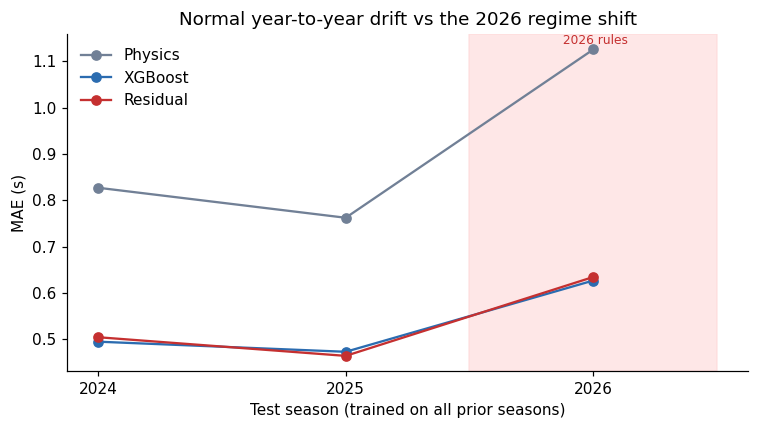

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for n in MODELS:
    s = season_mae[season_mae.model == n]
    ax.plot(s.test_season, s.MAE, marker='o', label=n, color=COLORS[n])
ax.axvspan(2025.5, 2026.5, color='#fed7d7', alpha=0.6)
ax.text(2026, ax.get_ylim()[1], ' 2026 rules', va='top', ha='center', fontsize=8, color='#c53030')
ax.set_xticks([2024, 2025, 2026]); ax.set_xlabel('Test season (trained on all prior seasons)')
ax.set_ylabel('MAE (s)'); ax.set_title('Normal year-to-year drift vs the 2026 regime shift')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/05_mae_by_test_season.png', dpi=150); plt.show()

**Figure 05.** With the full feature set, the two normal transitions sit around **0.47-0.50 s** for the boosted models, and that's the baseline year-to-year drift. At 2026 the error jumps to **~0.63 s**, about **+30%** above the average of the two normal years (~0.48 s), and that excess is the regime-shift effect. Compared with our first iteration (team names and 6 numeric features), every number here is about 20% lower (2026: 0.80 -> 0.63 s), but the *relative* jump has barely moved (+31% -> +30%): measuring pace makes the model better in every era rather than specifically closing the 2026 gap. The residual (physics-informed) model still tracks plain XGBoost almost exactly (0.634 vs 0.627 at 2026), so the physical priors don't buy cross-era robustness, and the physics baseline is just a weaker floor throughout.

### 2. Where the 2026 error lives: compound, team and circuit
We flag the genuinely **unseen** entities: the **Cadillac** team (new in 2026, no lineage) and the **Madrid** circuit (new track).

In [4]:
tr = df.season < 2026; te = df.season == 2026
yte = y_all[te].values
preds = {n: fit_predict(n, df, X_all, y_all, tr, te, XGB_PARAMS) for n in MODELS}
overall = pd.DataFrame({n: metrics(yte, preds[n]) for n in MODELS}).T.round(3)
print('Regime shift overall (train 2022-2025, test 2026):'); print(overall.to_string())

best = min(MODELS, key=lambda n: metrics(yte, preds[n])['MAE'])
dte = df[te]
bd_cmp = breakdown(dte, yte, preds[best], 'compound')
bd_team = breakdown(dte, yte, preds[best], 'team_lineage', unseen={'Cadillac'})
bd_circ = breakdown(dte, yte, preds[best], 'circuit', unseen={'Madrid'})
print('\nBreakdowns use the best 2026 model: %s' % best)
print('\nBy compound:'); print(bd_cmp.to_string(index=False))
print('\nBy team lineage:'); print(bd_team.to_string(index=False))
print('\nBy circuit (worst 6):'); print(bd_circ.head(6).to_string(index=False))

Regime shift overall (train 2022-2025, test 2026):
            MAE   RMSE
Physics   1.126  1.462
XGBoost   0.627  0.899
Residual  0.634  0.904

Breakdowns use the best 2026 model: XGBoost

By compound:
compound    n   MAE  RMSE  unseen
    SOFT 4198 0.688 1.023   False
  MEDIUM 6059 0.636 0.880   False
    HARD 7016 0.582 0.834   False

By team lineage:
   team_lineage    n   MAE  RMSE  unseen
       Cadillac 1306 1.013 1.492    True
   Aston Martin 1142 0.965 1.352   False
       Williams 1537 0.621 0.888   False
    Sauber/Audi 1576 0.610 0.825   False
   Haas F1 Team 1608 0.597 0.843   False
         Alpine 1710 0.588 0.806   False
        McLaren 1609 0.559 0.758   False
       Mercedes 1763 0.549 0.717   False
        Ferrari 1751 0.534 0.703   False
   Racing Bulls 1662 0.528 0.754   False
Red Bull Racing 1609 0.521 0.702   False

By circuit (worst 6):
   circuit    n   MAE  RMSE  unseen
    Madrid  953 1.023 1.353    True
    Monaco 1135 0.986 1.189   False
  Canadian  903 0.964

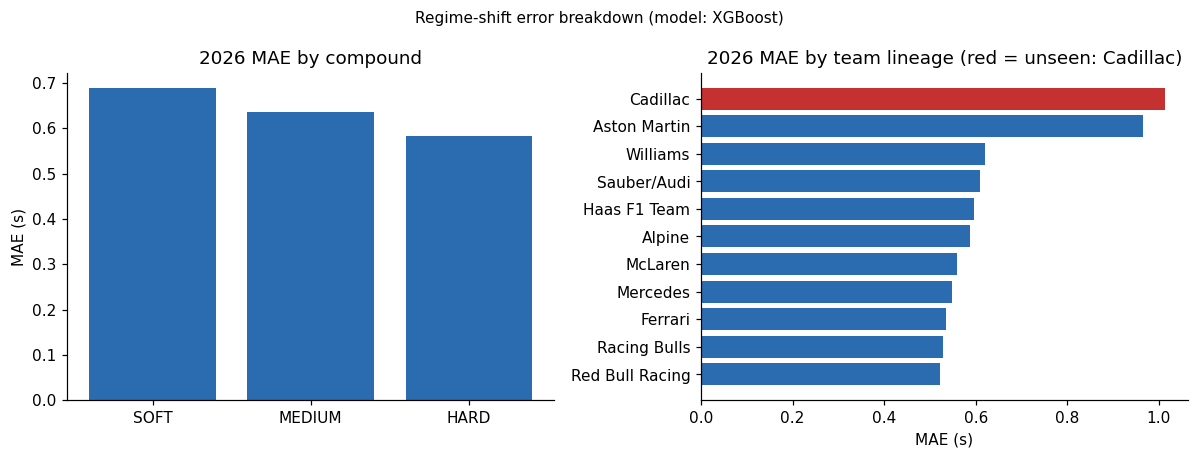

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].bar(bd_cmp.compound, bd_cmp.MAE, color='#2b6cb0')
axs[0].set_title('2026 MAE by compound'); axs[0].set_ylabel('MAE (s)')
ct = ['#c53030' if u else '#2b6cb0' for u in bd_team.unseen]
axs[1].barh(list(bd_team.team_lineage)[::-1], list(bd_team.MAE)[::-1], color=ct[::-1])
axs[1].set_title('2026 MAE by team lineage (red = unseen: Cadillac)'); axs[1].set_xlabel('MAE (s)')
fig.suptitle('Regime-shift error breakdown (model: %s)' % best, fontsize=10)
plt.tight_layout(); plt.savefig('figures/07_regime_breakdown.png', dpi=150); plt.show()

**Figure 07.** Error still concentrates where a regime shift predicts. The **unseen** entities are worst: **Cadillac** at 1.01 s and the new **Madrid** circuit at 1.02 s. Both improved a lot over our first iteration (1.54 s and 1.29 s), because the model now gets Cadillac's qualifying pace instead of falling back to an "average team", but they're still clearly the hardest cases. **Aston Martin** (0.97 s) remains the surprise: a *seen* team that's nearly as hard as the brand-new one, because its 2026 car behaves so differently from its 2022-2025 cars. Among compounds **SOFT** is hardest (0.69 s), the fastest-degrading and most situational tyre, and street-style circuits (Monaco, Canada, Las Vegas) top the circuit table.

### 3. Robustness: remove the races run after both titles were decided
Notebook 02 found no sign that champion teams ease off once both titles are settled, so we keep those 10 races. As a robustness check we rerun the drift-vs-shift comparison with them removed from **both** training and test data. If the conclusions hold either way, they don't depend on that choice.

In [6]:
keep = ~df.post_clinch.astype(bool)
rows = []
for tr_seasons, te_season in transitions:
    for label, m in [('all races', pd.Series(True, index=df.index)), ('post-clinch removed', keep)]:
        ev = evaluate_split(df, X_all, y_all, df.season.isin(tr_seasons) & m, (df.season == te_season) & m,
                            XGB_PARAMS, models=['XGBoost'])
        rows.append({'test_season': te_season, 'data': label, 'MAE': ev.loc['XGBoost', 'MAE']})
rob = pd.DataFrame(rows).pivot(index='test_season', columns='data', values='MAE')
rob.loc['2026 vs mean(2024, 2025)'] = rob.loc[2026] / rob.loc[[2024, 2025]].mean() - 1
print('XGBoost MAE (s); last row = relative jump at 2026')
rob.round(3)

XGBoost MAE (s); last row = relative jump at 2026


data,all races,post-clinch removed
test_season,,
2024,0.495,0.504
2025,0.473,0.493
2026,0.627,0.626
"2026 vs mean(2024, 2025)",0.295,0.256


**Read:** the two columns tell the same story. The 2026 jump is +30% with every race and +26% with the post-clinch races removed, and the normal years barely move, so the regime-shift result doesn't hinge on whether we keep the races run after the titles were decided.